<a href="https://colab.research.google.com/github/srihanreddy/Quantum-Hackathon/blob/main/Quantum_Random_Forest_Ensemble_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum Random Forest — Ensemble Classification
Kaggle-ready comparison of a classical Random Forest and a **quantum-kernel random-subspace ensemble**.

**Task:** Ensemble classification  
**Reference:** R02 — https://doi.org/10.1109/ACCESS.2025.3573244  
**Datasets:** Iris (D01), Breast Cancer Wisconsin Diagnostic (D03)  
**Metrics:** Accuracy, balanced accuracy, macro-F1, confusion matrix, AUROC, Brier score  
**Quantum cost:** Qubits, circuit depth, shots, circuit evaluations, training and inference time.

**Method note:** The quantum model below is a practical hybrid quantum-kernel ensemble inspired by the Quantum Random Forest task. Each member uses bootstrap sampling, a random PCA feature subset, a fidelity quantum kernel, and an SVC. It is not claimed to be an exact reproduction of the cited paper's architecture.

## 1. Setup

In [1]:
%pip install -q pennylane

In [2]:
import time, json, random, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pennylane as qml

from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, roc_auc_score, brier_score_loss)

SEED=42
random.seed(SEED); np.random.seed(SEED)
print("Python:", platform.python_version(), "| PennyLane:", qml.__version__)
print("Quantum backend: default.qubit (CPU simulator)")
OUT=Path("/kaggle/working/quantum_rf_results") if Path("/kaggle/working").exists() else Path("./quantum_rf_results")
OUT.mkdir(parents=True, exist_ok=True)

N_QUBITS=4
Q_DEPTH=2
N_ESTIMATORS=3
MAX_QUANTUM_TRAIN=100
N_PCA_COMPONENTS=6
FEATURES_PER_MEMBER=4
SHOTS=None  # analytic kernel; no finite-shot sampling in this run

Python: 3.13.16 | PennyLane: 0.45.1
Quantum backend: default.qubit (CPU simulator)


## 2. Load datasets

In [3]:
datasets={"Iris (D01)":load_iris(),
          "Breast Cancer Wisconsin (D03)":load_breast_cancer()}
for name,ds in datasets.items():
    print(name, "samples=",len(ds.data),"features=",ds.data.shape[1],
          "classes=",list(ds.target_names))

Iris (D01) samples= 150 features= 4 classes= [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Breast Cancer Wisconsin (D03) samples= 569 features= 30 classes= [np.str_('malignant'), np.str_('benign')]


## 3. Quantum fidelity feature map
A data point is encoded by a rotation embedding followed by a ring of entangling CNOT gates, repeated `Q_DEPTH` times. The kernel is the squared overlap between two encoded quantum states.

In [4]:
qdev=qml.device("default.qubit",wires=N_QUBITS,shots=SHOTS)

def feature_map(x):
    qml.AngleEmbedding(x,wires=range(N_QUBITS),rotation="Y")
    for _ in range(Q_DEPTH):
        for w in range(N_QUBITS-1):
            qml.CNOT(wires=[w,w+1])
        qml.CNOT(wires=[N_QUBITS-1,0])

@qml.qnode(qdev)
def fidelity_circuit(x1,x2):
    feature_map(x1)
    qml.adjoint(feature_map)(x2)
    return qml.expval(qml.Projector([0]*N_QUBITS,wires=range(N_QUBITS)))

def train_kernel(X):
    n=len(X); K=np.eye(n); calls=0; t=time.perf_counter()
    for i in range(n):
        for j in range(i+1,n):
            v=float(fidelity_circuit(X[i],X[j]))
            K[i,j]=v; K[j,i]=v; calls+=1
    return K,calls,time.perf_counter()-t

def cross_kernel(Xa,Xb):
    K=np.empty((len(Xa),len(Xb))); calls=0; t=time.perf_counter()
    for i in range(len(Xa)):
        for j in range(len(Xb)):
            K[i,j]=float(fidelity_circuit(Xa[i],Xb[j])); calls+=1
    return K,calls,time.perf_counter()-t

print(qml.draw(fidelity_circuit)(np.ones(N_QUBITS)*0.1,np.ones(N_QUBITS)*0.2))

0: ─╭AngleEmbedding(M0)─╭●───────╭X─╭●───────╭X─╭X†─────────╭X†─╭X†─────────╭X† ···
1: ─├AngleEmbedding(M0)─╰X─╭●────│──╰X─╭●────│──│───────╭X†─╰X†─│───────╭X†─╰X† ···
2: ─├AngleEmbedding(M0)────╰X─╭●─│─────╰X─╭●─│──│───╭X†─╰X†─────│───╭X†─╰X†──── ···
3: ─╰AngleEmbedding(M0)───────╰X─╰●───────╰X─╰●─╰X†─╰X†─────────╰X†─╰X†──────── ···

0: ··· ─╭AngleEmbedding(M1)†─┤ ╭<|0000⟩⟨0000|>
1: ··· ─├AngleEmbedding(M1)†─┤ ├<|0000⟩⟨0000|>
2: ··· ─├AngleEmbedding(M1)†─┤ ├<|0000⟩⟨0000|>
3: ··· ─╰AngleEmbedding(M1)†─┤ ╰<|0000⟩⟨0000|>

M0 = 
[0.1 0.1 0.1 0.1]
M1 = 
[0.2 0.2 0.2 0.2]


## 4. Metrics and preprocessing

In [5]:
def prepare(ds,seed):
    Xtr,Xte,ytr,yte=train_test_split(ds.data,ds.target,test_size=.25,
        random_state=seed,stratify=ds.target)
    scaler=StandardScaler()
    Xtr_s=scaler.fit_transform(Xtr); Xte_s=scaler.transform(Xte)
    ncomp=min(N_PCA_COMPONENTS,Xtr_s.shape[1],Xtr_s.shape[0])
    pca=PCA(n_components=ncomp,random_state=seed)
    A=pca.fit_transform(Xtr_s); B=pca.transform(Xte_s)
    angle=MinMaxScaler(feature_range=(-np.pi,np.pi))
    A=angle.fit_transform(A); B=angle.transform(B)
    return Xtr_s,Xte_s,A,B,ytr,yte

def score_metrics(y,p,nclass):
    pred=np.argmax(p,axis=1)
    out={"accuracy":accuracy_score(y,pred),
         "balanced_accuracy":balanced_accuracy_score(y,pred),
         "macro_F1":f1_score(y,pred,average="macro")}
    if nclass==2:
        out["AUROC_binary"]=roc_auc_score(y,p[:,1])
        out["Brier_score"]=brier_score_loss(y,p[:,1])
    else:
        yhot=np.eye(nclass)[y]
        out["AUROC_macro_ovr"]=roc_auc_score(yhot,p,average="macro",multi_class="ovr")
        out["Brier_score"]=float(np.mean(np.sum((p-yhot)**2,axis=1)))
    return out

## 5. Train classical Random Forest and quantum ensemble
The classical Random Forest uses the full training split. The quantum ensemble uses a capped training pool for practical runtime. Each member bootstraps that pool and chooses a random contiguous subset of four PCA dimensions. Probability outputs are averaged across members.

In [6]:
metrics_rows=[]; resource_rows=[]; saved_confusions={}
for di,(name,ds) in enumerate(datasets.items()):
    print("\n###",name)
    Xtr_s,Xte_s,Xtr_q,Xte_q,ytr,yte=prepare(ds,SEED+di)
    nclass=len(ds.target_names)

    rf=RandomForestClassifier(n_estimators=200,random_state=SEED,class_weight="balanced")
    t=time.perf_counter(); rf.fit(Xtr_s,ytr); rf_train=time.perf_counter()-t
    t=time.perf_counter(); rfprob=rf.predict_proba(Xte_s); rf_inf=time.perf_counter()-t
    rfpred=np.argmax(rfprob,axis=1)
    metrics_rows.append({"dataset":name,"model":"Classical Random Forest",**score_metrics(yte,rfprob,nclass)})
    resource_rows.append({"dataset":name,"model":"Classical Random Forest","qubits":0,
        "circuit_depth":"N/A","shots":"N/A","circuit_evaluations":0,
        "training_seconds":rf_train,"inference_seconds":rf_inf})
    saved_confusions[(name,"Classical Random Forest")]=(yte,rfpred)
    print("Classical RF:",score_metrics(yte,rfprob,nclass))

    rng=np.random.default_rng(SEED+di+500)
    if len(ytr)>MAX_QUANTUM_TRAIN:
        ix=rng.choice(len(ytr),MAX_QUANTUM_TRAIN,replace=False)
        pool=Xtr_q[ix]; ypool=ytr[ix]
    else:
        pool=Xtr_q; ypool=ytr
    probs_members=[]; qtrain=0.; qinf=0.; qcalls=0
    for m in range(N_ESTIMATORS):
        mrng=np.random.default_rng(SEED+di*100+m)
        boot=mrng.choice(len(ypool),len(ypool),replace=True)
        nfeat=min(FEATURES_PER_MEMBER,pool.shape[1])
        start=int(mrng.integers(0,pool.shape[1]-nfeat+1))
        cols=np.arange(start,start+nfeat)
        Xm=pool[boot][:,cols]; ym=ypool[boot]; Xtm=Xte_q[:,cols]

        Ktr,nc1,sec1=train_kernel(Xm)
        Ktr+=1e-8*np.eye(len(Ktr))
        clf=SVC(kernel="precomputed",probability=True,class_weight="balanced",
                random_state=SEED+m)
        t=time.perf_counter(); clf.fit(Ktr,ym); fitsec=time.perf_counter()-t
        Kte,nc2,sec2=cross_kernel(Xtm,Xm)
        raw=clf.predict_proba(Kte)
        aligned=np.zeros((len(yte),nclass))
        for cidx,c in enumerate(clf.classes_): aligned[:,int(c)]=raw[:,cidx]
        probs_members.append(aligned)
        qtrain+=sec1+fitsec; qinf+=sec2; qcalls+=nc1+nc2
        print(f"Quantum member {m+1}/{N_ESTIMATORS} complete — kernel train {sec1:.1f}s, inference kernel {sec2:.1f}s")
    qprob=np.mean(probs_members,axis=0); qpred=np.argmax(qprob,axis=1)
    qmetrics=score_metrics(yte,qprob,nclass)
    metrics_rows.append({"dataset":name,"model":"Quantum Random-Subspace Ensemble",**qmetrics})
    resource_rows.append({"dataset":name,"model":"Quantum Random-Subspace Ensemble",
        "qubits":N_QUBITS,"modes":"N/A (qubit-based)","circuit_depth":Q_DEPTH* (N_QUBITS+1),
        "shots":"Analytic (shots=None)","circuit_evaluations":qcalls,
        "training_seconds":qtrain,"inference_seconds":qinf,
        "ensemble_members":N_ESTIMATORS,"quantum_train_sample_cap":MAX_QUANTUM_TRAIN})
    saved_confusions[(name,"Quantum Random-Subspace Ensemble")]=(yte,qpred)
    print("Quantum ensemble:",qmetrics,"circuit calls:",qcalls)


### Iris (D01)
Classical RF: {'accuracy': 0.8947368421052632, 'balanced_accuracy': np.float64(0.8974358974358975), 'macro_F1': 0.8968253968253969, 'AUROC_macro_ovr': np.float64(0.9923076923076923), 'Brier_score': 0.10608947368421051}
Quantum member 1/3 complete — kernel train 45.6s, inference kernel 18.9s
Quantum member 2/3 complete — kernel train 25.8s, inference kernel 18.1s
Quantum member 3/3 complete — kernel train 24.4s, inference kernel 19.0s
Quantum ensemble: {'accuracy': 0.9473684210526315, 'balanced_accuracy': np.float64(0.9487179487179488), 'macro_F1': 0.9487179487179488, 'AUROC_macro_ovr': np.float64(0.9897435897435898), 'Brier_score': 0.113527712680246} circuit calls: 26250

### Breast Cancer Wisconsin (D03)
Classical RF: {'accuracy': 0.9440559440559441, 'balanced_accuracy': np.float64(0.9361635220125786), 'macro_F1': 0.9395604395604396, 'AUROC_binary': np.float64(0.9812368972746331), 'Brier_score': np.float64(0.042006468531468534)}
Quantum member 1/3 complete — kernel tra

## 6. Results and confusion matrices

,dataset,model,accuracy,balanced_accuracy,macro_F1,AUROC_macro_ovr,Brier_score,AUROC_binary
0,Iris (D01),Classical Random Forest,0.894737,0.897436,0.896825,0.992308,0.106089,NaN
1,Iris (D01),Quantum Random-Subspace Ensemble,0.947368,0.948718,0.948718,0.989744,0.113528,NaN
2,Breast Cancer Wisconsin (D03),Classical Random Forest,0.944056,0.936164,0.939560,NaN,0.042006,0.981237
3,Breast Cancer Wisconsin (D03),Quantum Random-Subspace Ensemble,0.909091,0.896751,0.901374,NaN,0.102110,0.961635


,dataset,model,qubits,circuit_depth,shots,circuit_evaluations,training_seconds,inference_seconds,modes,ensemble_members,quantum_train_sample_cap
0,Iris (D01),Classical Random Forest,0,N/A,N/A,0,1.411580,0.044716,NaN,NaN,NaN
1,Iris (D01),Quantum Random-Subspace Ensemble,4,10,Analytic (shots=None),26250,95.841546,55.970630,N/A (qubit-based),3.0,100.0
2,Breast Cancer Wisconsin (D03),Classical Random Forest,0,N/A,N/A,0,0.481384,0.012089,NaN,NaN,NaN
3,Breast Cancer Wisconsin (D03),Quantum Random-Subspace Ensemble,4,10,Analytic (shots=None),57750,73.445008,208.558795,N/A (qubit-based),3.0,100.0


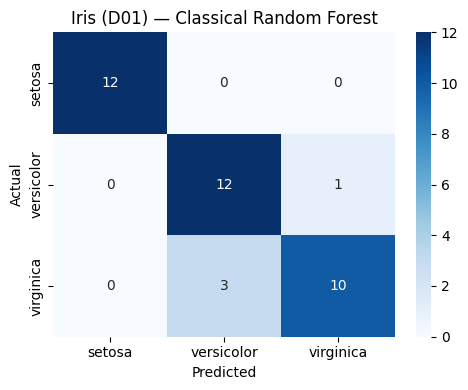

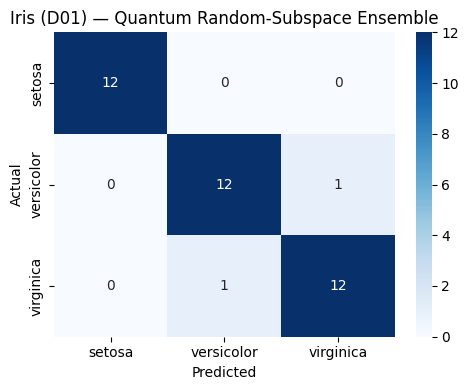

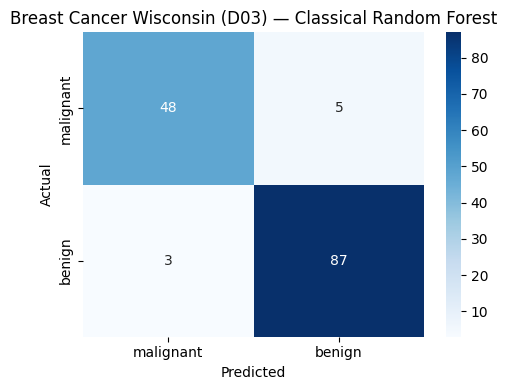

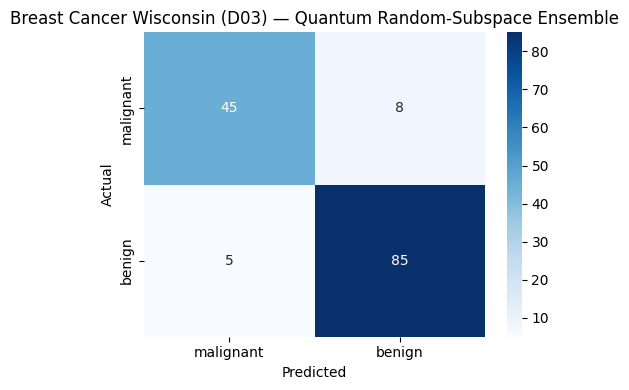

In [7]:
metrics_df=pd.DataFrame(metrics_rows)
resources_df=pd.DataFrame(resource_rows)
display(metrics_df)
display(resources_df)
for (name,model),(yt,yp) in saved_confusions.items():
    cm=confusion_matrix(yt,yp)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",
        xticklabels=datasets[name].target_names,yticklabels=datasets[name].target_names)
    plt.title(f"{name} — {model}"); plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.tight_layout(); plt.show()

## 7. Quantum resource analysis

In [8]:
print("Qubits:",N_QUBITS)
print("Entangling feature-map repetitions:",Q_DEPTH)
print("Structural depth estimate:",Q_DEPTH*(N_QUBITS+1))
print("Shots:", "analytic (shots=None)" if SHOTS is None else SHOTS)
print("Modes: N/A — qubit-based implementation")
display(resources_df[resources_df.model=="Quantum Random-Subspace Ensemble"])

Qubits: 4
Entangling feature-map repetitions: 2
Structural depth estimate: 10
Shots: analytic (shots=None)
Modes: N/A — qubit-based implementation


,dataset,model,qubits,circuit_depth,shots,circuit_evaluations,training_seconds,inference_seconds,modes,ensemble_members,quantum_train_sample_cap
1,Iris (D01),Quantum Random-Subspace Ensemble,4,10,Analytic (shots=None),26250,95.841546,55.970630,N/A (qubit-based),3.0,100.0
3,Breast Cancer Wisconsin (D03),Quantum Random-Subspace Ensemble,4,10,Analytic (shots=None),57750,73.445008,208.558795,N/A (qubit-based),3.0,100.0


## 8. Export results

In [9]:
metrics_df.to_csv(OUT/"classification_metrics.csv",index=False)
resources_df.to_csv(OUT/"quantum_resource_analysis.csv",index=False)
with open(OUT/"experiment_summary.json","w") as f:
    json.dump({"seed":SEED,"n_qubits":N_QUBITS,"q_depth":Q_DEPTH,
        "shots":SHOTS,"n_estimators":N_ESTIMATORS,
        "max_quantum_train":MAX_QUANTUM_TRAIN,
        "metrics":metrics_rows,"resources":resource_rows},f,indent=2)
print("Saved files:",[p.name for p in OUT.iterdir()])

Saved files: ['classification_metrics.csv', 'experiment_summary.json', 'quantum_resource_analysis.csv']


## 9. Interpretation and limitations
- Higher accuracy, balanced accuracy, macro-F1 and AUROC are better.
- Lower Brier score indicates better probability calibration.
- Use confusion matrices to inspect class-specific errors.
- The quantum model uses a capped training subset, whereas classical Random Forest uses all training data. This is an important fairness limitation.
- The kernel uses analytic expectations (`shots=None`), not finite-shot measurements.
- `default.qubit` is a CPU simulator; the Kaggle T4 does not accelerate these quantum circuit evaluations.
- This experiment does not establish quantum advantage. It is a small-scale simulated quantum-kernel ensemble comparison.

## References
1. R02: https://doi.org/10.1109/ACCESS.2025.3573244
2. Iris: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html
3. Breast Cancer Wisconsin Diagnostic: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html
4. PennyLane: https://docs.pennylane.ai/